In [ ]:
Final Output ------># Enterprise Data Architecture & Reconciliation

In [2]:
# ===================================================================
# PHASE 1: SQL EXTRACTION
# ===================================================================
import time
import sqlite3
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

t0 = time.time()

DB_PATH   = "enterprise_database.db"       
LOG_PATH  = "server_logs.txt"
FX_PATH   = "daily_exchange_rates.csv"

conn = sqlite3.connect(DB_PATH)

query = """
WITH ranked AS (
    SELECT user_id, name, status, updated_at,
           ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY updated_at DESC) AS rn
    FROM users
)
SELECT user_id, name, status, updated_at
FROM ranked
WHERE rn = 1 AND status = 'Active';
"""
df_active_users = pd.read_sql(query, conn)
conn.close()

print(f"Active users (latest status): {len(df_active_users):,}")
assert df_active_users["user_id"].is_unique
df_active_users.head()

Active users (latest status): 14,183


,user_id,name,status,updated_at
0,U-00001,User_U-00001,Active,2023-01-28 14:00:00
1,U-00003,User_U-00003,Active,2023-01-22 14:00:00
2,U-00005,User_U-00005,Active,2023-01-17 14:00:00
3,U-00006,User_U-00006,Active,2023-01-05 14:00:00
4,U-00007,User_U-00007,Active,2023-01-27 14:00:00


In [3]:
# ===================================================================
# PHASE 2: REGEX & UNSTRUCTURED DATA WRANGLING
# ===================================================================

df_logs = pd.read_csv(LOG_PATH)
print(f"Raw log rows: {len(df_logs):,}")

df_logs = df_logs[~df_logs["Raw_Server_Log"].str.contains("ERROR", regex=False)]
print(f"After dropping ERROR rows: {len(df_logs):,}")

pattern = (
    r'^\[(?P<Date>\d{4}-\d{2}-\d{2})[^\]]*\]'      
    r'.*?"u"\s*:\s*"(?P<User_ID>[^"]+)"'              
    r'.*?"item_code"\s*:\s*"(?P<Product_ID>[^"]+)"'   
    r'.*?"eur_val"\s*:\s*(?P<Euro_Value>-?\d+(?:\.\d+)?)'  
)
extracted_data = df_logs["Raw_Server_Log"].str.extract(pattern)

extracted_data["Date"] = pd.to_datetime(extracted_data["Date"])
extracted_data["Euro_Value"] = extracted_data["Euro_Value"].astype(float)

n_bad = extracted_data.isna().any(axis=1).sum()
print(f"Rows that failed to parse: {n_bad}")
extracted_data = extracted_data.dropna().reset_index(drop=True)
extracted_data.head()

Raw log rows: 100,000
After dropping ERROR rows: 94,902
Rows that failed to parse: 0


,Date,User_ID,Product_ID,Euro_Value
0,2023-03-15,U-19484,PRD-874,3404.44
1,2023-05-09,U-18932,PRD-905,3406.21
2,2023-10-21,U-15882,PRD-284,164.08
3,2023-01-10,U-22781,PRD-665,26.80
4,2023-05-23,U-13348,PRD-589,4964.77


In [4]:
# ===================================================================
# PHASE 3: FINANCIAL RECONCILIATION & MERGING
# ===================================================================

df_fx = pd.read_csv(FX_PATH, parse_dates=["Date"]).sort_values("Date")
print(f"Missing rates before fill: {df_fx['EUR_to_USD'].isna().sum()}")

df_fx["EUR_to_USD"] = df_fx["EUR_to_USD"].ffill()
print(f"Missing rates after fill:  {df_fx['EUR_to_USD'].isna().sum()}")

n_tx = len(extracted_data)
df_merged = extracted_data.merge(df_fx, on="Date", how="left")
assert len(df_merged) == n_tx and df_merged["EUR_to_USD"].notna().all()

df_final = df_merged.merge(
    df_active_users[["user_id", "name"]],
    left_on="User_ID", right_on="user_id", how="inner"
).drop(columns="user_id")

df_final["USD_Revenue"] = df_final["Euro_Value"] * df_final["EUR_to_USD"]

print(f"Valid transactions: {n_tx:,}  ->  after active-user filter: {len(df_final):,}")
print(f"Dropped (user not Active / not in HR DB): {n_tx - len(df_final):,}")
df_final.head()

Missing rates before fill: 104
Missing rates after fill:  0
Valid transactions: 94,902  ->  after active-user filter: 53,899
Dropped (user not Active / not in HR DB): 41,003


,Date,User_ID,Product_ID,Euro_Value,EUR_to_USD,name,USD_Revenue
0,2023-03-15,U-19484,PRD-874,3404.44,1.178232,User_U-19484,4011.220772
1,2023-10-21,U-15882,PRD-284,164.08,1.075350,User_U-15882,176.443420
2,2023-01-10,U-22781,PRD-665,26.80,1.127128,User_U-22781,30.207030
3,2023-10-20,U-22062,PRD-363,48.63,1.075350,User_U-22062,52.294268
4,2023-12-02,U-22146,PRD-223,960.60,1.066142,User_U-22146,1024.135923


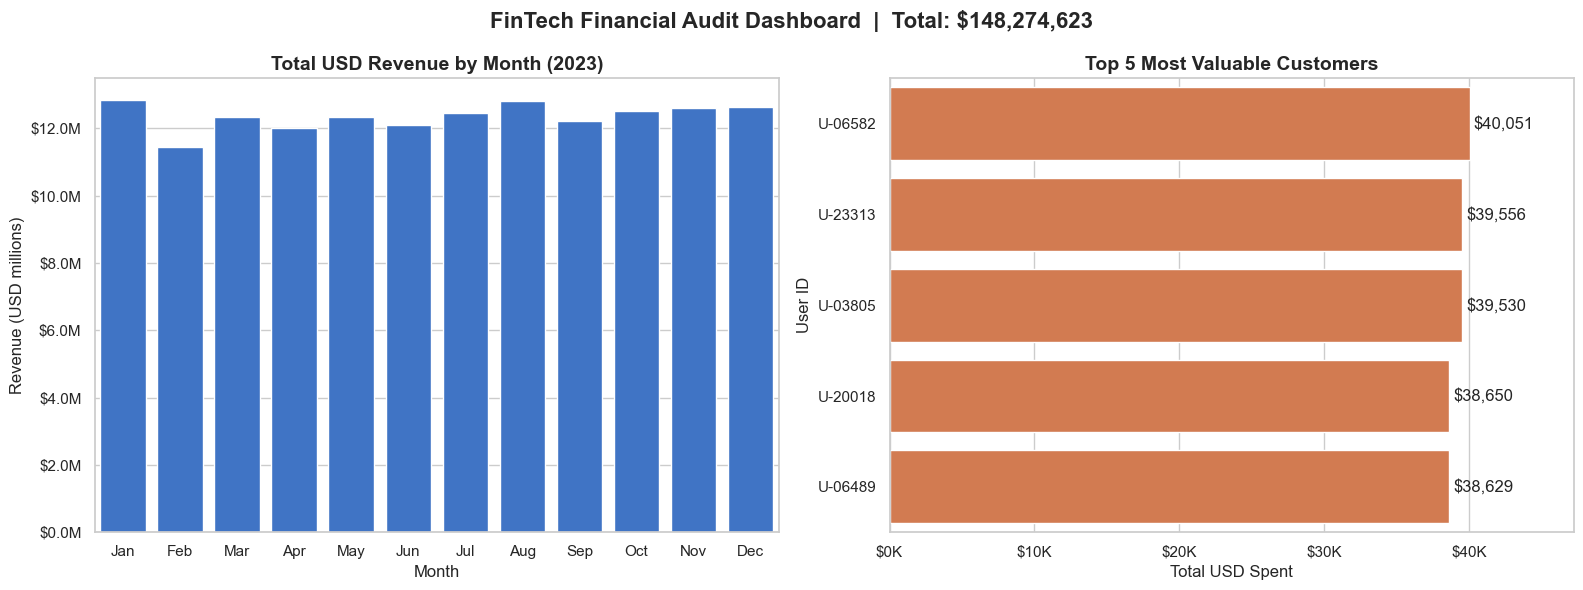

Pipeline runtime: 10.3 s (requirement: < 120 s)


In [5]:
# ===================================================================
# PHASE 4: AGGREGATION & VISUALIZATION (CFO DASHBOARD)
# ===================================================================

monthly = (df_final
           .groupby(df_final["Date"].dt.to_period("M"))["USD_Revenue"].sum()
           .reset_index())
monthly["Month"] = monthly["Date"].dt.strftime("%b")

top5 = (df_final.groupby("User_ID")["USD_Revenue"].sum()
        .nlargest(5).reset_index())

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=monthly, x="Month", y="USD_Revenue", color="#2a6fdb", ax=axes[0])
axes[0].set_title("Total USD Revenue by Month (2023)", fontsize=14, weight="bold")
axes[0].set_xlabel("Month"); axes[0].set_ylabel("Revenue (USD millions)")
axes[0].yaxis.set_major_formatter(lambda v, _: f"${v/1e6:,.1f}M")

sns.barplot(data=top5, x="USD_Revenue", y="User_ID", color="#e8743b", ax=axes[1])
axes[1].set_title("Top 5 Most Valuable Customers", fontsize=14, weight="bold")
axes[1].set_xlabel("Total USD Spent"); axes[1].set_ylabel("User ID")
axes[1].xaxis.set_major_formatter(lambda v, _: f"${v/1e3:,.0f}K")
for c in axes[1].containers:
    axes[1].bar_label(c, labels=[f"${v:,.0f}" for v in top5["USD_Revenue"]], padding=3)
axes[1].set_xlim(0, top5["USD_Revenue"].max() * 1.18)

fig.suptitle(f"FinTech Financial Audit Dashboard  |  Total: ${df_final['USD_Revenue'].sum():,.0f}",
             fontsize=16, weight="bold")
plt.tight_layout()
plt.savefig("cfo_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Pipeline runtime: {time.time() - t0:.1f} s (requirement: < 120 s)")

In [8]:
# ---- AUDIT: verify every claim in the project statement ----

fx_raw = pd.read_csv(FX_PATH, parse_dates=["Date"])
naive = extracted_data.merge(fx_raw.dropna(), on="Date", how="inner")
lost = 1 - len(naive) / len(extracted_data)
print(f"Naive inner join would lose {lost:.1%} of transactions (statement says ~28%)")
print(f"ffill pipeline keeps {len(df_merged):,} / {len(extracted_data):,} transactions")

assert not df_logs["Raw_Server_Log"].str.contains("ERROR").any()
assert extracted_data.notna().all().all()

con = sqlite3.connect(DB_PATH)
raw = pd.read_sql("SELECT * FROM users", con); con.close()
latest = raw.sort_values("updated_at").groupby("user_id").tail(1)
expected = set(latest.loc[latest.status == "Active", "user_id"])
assert set(df_active_users["user_id"]) == expected and df_active_users["user_id"].is_unique
print(f"Users in history table: {raw['user_id'].nunique():,} | latest-status Active: {len(expected):,}")

assert df_final["USD_Revenue"].notna().all()
assert abs(monthly["USD_Revenue"].sum() - df_final["USD_Revenue"].sum()) < 1e-6
print("All audit checks passed")

Naive inner join would lose 28.4% of transactions (statement says ~28%)
ffill pipeline keeps 94,902 / 94,902 transactions
Users in history table: 25,000 | latest-status Active: 14,183
All audit checks passed


In [9]:
# ---- Extra cross-check: parse the JSON payload directly and compare with the regex result ----
import json
payload = df_logs["Raw_Server_Log"].str.extract(r"payload=(\{.*\})")[0]
parsed = pd.json_normalize(payload.map(json.loads))      
assert (parsed["u"].values == extracted_data["User_ID"].values).all()
assert (parsed["item_code"].values == extracted_data["Product_ID"].values).all()
assert (parsed["eur_val"].values == extracted_data["Euro_Value"].values).all()
print("JSON-payload parse matches regex extraction on all rows")

# ---- Exclusion impact: revenue from users who are NOT currently Active ----
all_usd = (df_merged["Euro_Value"] * df_merged["EUR_to_USD"]).sum()
kept_usd = df_final["USD_Revenue"].sum()
print(f"Revenue of all valid transactions : ${all_usd:,.0f}")
print(f"Revenue from Active users (kept)  : ${kept_usd:,.0f}")
print(f"Excluded (non-Active users)       : ${all_usd - kept_usd:,.0f} ({1 - kept_usd/all_usd:.1%})")

JSON-payload parse matches regex extraction on all rows
Revenue of all valid transactions : $261,241,852
Revenue from Active users (kept)  : $148,274,623
Excluded (non-Active users)       : $112,967,229 (43.2%)
